# Deep Q-Network — Cliff Walking

درس: یادگیری تقویتی عمیق  
DQN از پایه روی محیط Cliff Walking
(گرید 12*4 )
## ساختار پروژه
1. Environment — کلاس `CliffWalkingEnvironment`
2. Neural Network — کلاس `DQNetwork`
3. Replay Buffer — کلاس `ReplayBuffer`
4. DQN Agent — کلاس `DQNAgent`
5. Training / Evaluation / Visualization


In [ ]:
# Part 1 - Cliff Walking Environment

class CliffWalkingEnvironment:
    def __init__(self, grid_height=4, grid_width=12):
        # Grid size
        self.grid_height = grid_height
        self.grid_width = grid_width

        # Special positions
        self.start_position = (3, 0)
        self.goal_position = (3, 11)

        # Cliff cells: (3,1) to (3,10)
        self.cliff_positions = [(3, col) for col in range(1, 11)]

        # Action mapping: 0=up, 1=down, 2=left, 3=right
        self.action_map = {
            0: (-1, 0),   # up
            1: (1, 0),    # down
            2: (0, -1),   # left
            3: (0, 1)     # right
        }

        # Useful sizes for later parts
        self.action_size = 4
        self.state_size = self.grid_height * self.grid_width

        # Initial agent position
        self.agent_position = self.start_position

    def reset(self):
        self.agent_position = self.start_position
        return self.get_state_representation()

    def step(self, action):
        # Validate action
        if action not in self.action_map:
            raise ValueError(f"Invalid action {action}. Valid actions are 0, 1, 2, 3.")

        current_row, current_col = self.agent_position
        delta_row, delta_col = self.action_map[action]

        # Compute next position
        new_row = current_row + delta_row
        new_col = current_col + delta_col

        # Keep agent inside grid boundaries
        new_row = max(0, min(new_row, self.grid_height - 1))
        new_col = max(0, min(new_col, self.grid_width - 1))

        # Update position
        self.agent_position = (new_row, new_col)

        # Check terminal conditions and rewards
        if self.agent_position == self.goal_position:
            reward = 0
            done = True

        elif self.agent_position in self.cliff_positions:
            reward = -100
            done = True
            self.agent_position = self.start_position

        else:
            reward = -1
            done = False

        next_state = self.get_state_representation()
        info = {}

        return next_state, reward, done, info

    def get_state_representation(self):
        row, col = self.agent_position
        return row * self.grid_width + col

    def render(self):
        grid = [["." for _ in range(self.grid_width)] for _ in range(self.grid_height)]

        # Mark special cells
        start_row, start_col = self.start_position
        goal_row, goal_col = self.goal_position

        grid[start_row][start_col] = "S"
        grid[goal_row][goal_col] = "G"

        for row, col in self.cliff_positions:
            grid[row][col] = "C"

        # Mark agent last so it is visible
        agent_row, agent_col = self.agent_position
        grid[agent_row][agent_col] = "A"

        for row in grid:
            print(" ".join(row))
        print()


# Quick test
env = CliffWalkingEnvironment()

print("Initial state:")
state = env.reset()
print("State =", state)
env.render()

print("Move UP")
next_state, reward, done, info = env.step(0)
print("Next state =", next_state, "| Reward =", reward, "| Done =", done)
env.render()

print("Reset and move RIGHT into cliff")
env.reset()
next_state, reward, done, info = env.step(3)
print("Next state =", next_state, "| Reward =", reward, "| Done =", done)
env.render()


Initial state:
State = 36
. . . . . . . . . . . .
. . . . . . . . . . . .
. . . . . . . . . . . .
A C C C C C C C C C C G

Move UP
Next state = 24 | Reward = -1 | Done = False
. . . . . . . . . . . .
. . . . . . . . . . . .
A . . . . . . . . . . .
S C C C C C C C C C C G

Reset and move RIGHT into cliff
Next state = 36 | Reward = -100 | Done = True
. . . . . . . . . . . .
. . . . . . . . . . . .
. . . . . . . . . . . .
A C C C C C C C C C C G



In [ ]:
# Part 1 Tests

def test_environment():
    env = CliffWalkingEnvironment()

    print("Test 1: Reset")
    state = env.reset()
    assert env.agent_position == (3, 0), "Reset failed: agent not at start"
    assert state == 36, f"Reset failed: expected state 36, got {state}"
    print("Passed\n")

    print("Test 2: Move UP from start")
    env.reset()
    next_state, reward, done, _ = env.step(0)  # up
    assert env.agent_position == (2, 0), f"Expected position (2,0), got {env.agent_position}"
    assert next_state == 24, f"Expected state 24, got {next_state}"
    assert reward == -1, f"Expected reward -1, got {reward}"
    assert done is False, f"Expected done False, got {done}"
    print("Passed\n")

    print("Test 3: Move RIGHT into cliff")
    env.reset()
    next_state, reward, done, _ = env.step(3)  # right
    assert reward == -100, f"Expected reward -100, got {reward}"
    assert done is True, f"Expected done True, got {done}"
    assert env.agent_position == (3, 0), f"Expected reset to start, got {env.agent_position}"
    assert next_state == 36, f"Expected state 36 after cliff reset, got {next_state}"
    print("Passed\n")

    print("Test 4: Move LEFT at left boundary")
    env.reset()
    next_state, reward, done, _ = env.step(2)  # left
    assert env.agent_position == (3, 0), f"Expected position (3,0), got {env.agent_position}"
    assert next_state == 36, f"Expected state 36, got {next_state}"
    assert reward == -1, f"Expected reward -1, got {reward}"
    assert done is False, f"Expected done False, got {done}"
    print("Passed\n")

    print("Test 5: Move UP at top boundary")
    env.agent_position = (0, 5)
    next_state, reward, done, _ = env.step(0)  # up
    assert env.agent_position == (0, 5), f"Expected position (0,5), got {env.agent_position}"
    assert next_state == 5, f"Expected state 5, got {next_state}"
    assert reward == -1, f"Expected reward -1, got {reward}"
    assert done is False, f"Expected done False, got {done}"
    print("Passed\n")

    print("Test 6: Stay at goal when moving DOWN at bottom boundary")
    env.agent_position = (3, 11)  # goal cell
    next_state, reward, done, _ = env.step(1)  # down
    assert env.agent_position == (3, 11), f"Expected position (3,11), got {env.agent_position}"
    assert next_state == 47, f"Expected state 47, got {next_state}"
    assert reward == 0, f"Expected reward 0, got {reward}"
    assert done is True, f"Expected done True, got {done}"
    print("Passed\n")

    print("Test 7: Reach goal from (2,11) -> DOWN")
    env.agent_position = (2, 11)
    next_state, reward, done, _ = env.step(1)  # down
    assert env.agent_position == (3, 11), f"Expected position (3,11), got {env.agent_position}"
    assert next_state == 47, f"Expected state 47, got {next_state}"
    assert reward == 0, f"Expected reward 0, got {reward}"
    assert done is True, f"Expected done True, got {done}"
    print("Passed\n")

    print("All tests passed successfully!")


test_environment()


Test 1: Reset
Passed

Test 2: Move UP from start
Passed

Test 3: Move RIGHT into cliff
Passed

Test 4: Move LEFT at left boundary
Passed

Test 5: Move UP at top boundary
Passed

Test 6: Stay at goal when moving DOWN at bottom boundary
Passed

Test 7: Reach goal from (2,11) -> DOWN
Passed

All tests passed successfully!


In [ ]:
# Simple Animation

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.animation import FuncAnimation
from IPython.display import HTML


def draw_env(ax, env):
    ax.clear()

    # Draw grid cells
    for row in range(env.grid_height):
        for col in range(env.grid_width):
            color = "white"

            if (row, col) == env.start_position:
                color = "lightgreen"
            elif (row, col) == env.goal_position:
                color = "gold"
            elif (row, col) in env.cliff_positions:
                color = "tomato"

            rect = patches.Rectangle((col, env.grid_height - 1 - row), 1, 1,
                                     linewidth=1, edgecolor='black', facecolor=color)
            ax.add_patch(rect)

    # Draw agent
    agent_row, agent_col = env.agent_position
    agent_x = agent_col + 0.5
    agent_y = env.grid_height - 1 - agent_row + 0.5
    ax.plot(agent_x, agent_y, 'bo', markersize=12)

    # Labels
    sr, sc = env.start_position
    gr, gc = env.goal_position
    ax.text(sc + 0.5, env.grid_height - 1 - sr + 0.5, "S", ha='center', va='center', fontsize=12, color='black')
    ax.text(gc + 0.5, env.grid_height - 1 - gr + 0.5, "G", ha='center', va='center', fontsize=12, color='black')

    for r, c in env.cliff_positions:
        ax.text(c + 0.5, env.grid_height - 1 - r + 0.5, "C", ha='center', va='center', fontsize=10, color='black')

    ax.set_xlim(0, env.grid_width)
    ax.set_ylim(0, env.grid_height)
    ax.set_aspect('equal')
    ax.axis('off')


def animate_episode(actions, interval=700):
    env = CliffWalkingEnvironment()
    env.reset()

    # Save environment states
    positions = [env.agent_position]
    rewards = [None]
    dones = [False]

    for action in actions:
        _, reward, done, _ = env.step(action)
        positions.append(env.agent_position)
        rewards.append(reward)
        dones.append(done)
        if done:
            break

    fig, ax = plt.subplots(figsize=(12, 4))

    def update(frame):
        env.agent_position = positions[frame]
        draw_env(ax, env)

        title = f"Step {frame}"
        if frame > 0:
            title += f" | Reward: {rewards[frame]} | Done: {dones[frame]}"
        ax.set_title(title, fontsize=14)

    anim = FuncAnimation(fig, update, frames=len(positions), interval=interval, repeat=False)
    plt.close(fig)
    return HTML(anim.to_jshtml())


In [ ]:
# Save animation as GIF
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import FileLink
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def save_episode_gif(actions, filename="cliff_walking.gif", interval=500):
    env = CliffWalkingEnvironment()
    env.reset()

    positions = [env.agent_position]
    rewards = [None]
    dones = [False]

    for action in actions:
        _, reward, done, _ = env.step(action)
        positions.append(env.agent_position)
        rewards.append(reward)
        dones.append(done)
        if done:
            break

    fig, ax = plt.subplots(figsize=(12, 4))

    def update(frame):
        env.agent_position = positions[frame]
        draw_env(ax, env)

        title = f"Step {frame}"
        if frame > 0:
            title += f" | Reward: {rewards[frame]} | Done: {dones[frame]}"
        ax.set_title(title, fontsize=14)

    anim = FuncAnimation(fig, update, frames=len(positions), interval=interval, repeat=False)
    anim.save(filename, writer=PillowWriter(fps=max(1, 1000 // interval)))
    plt.close(fig)

    print(f"Saved GIF as: {filename}")
    return FileLink(filename)


### Cliff Fall Example

Saved GIF as: cliff_fall.gif


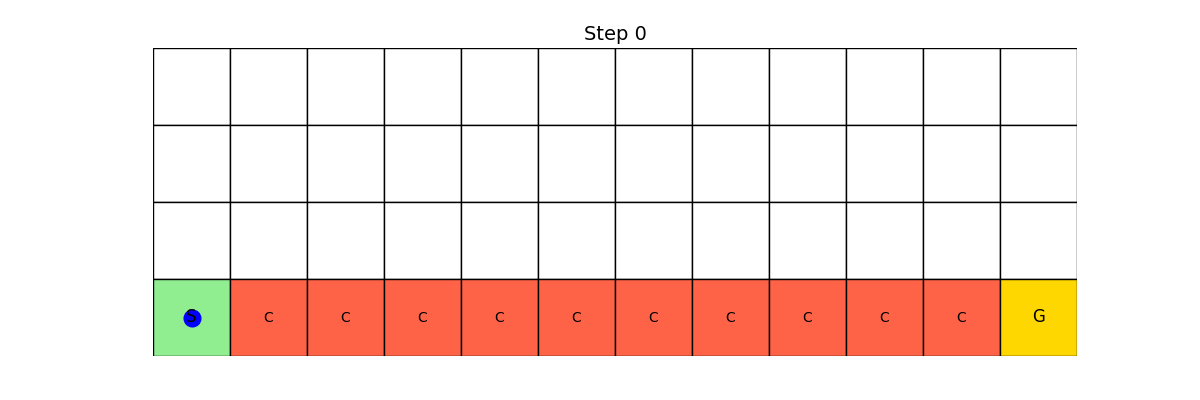

### Goal Path Example

Saved GIF as: goal_path.gif


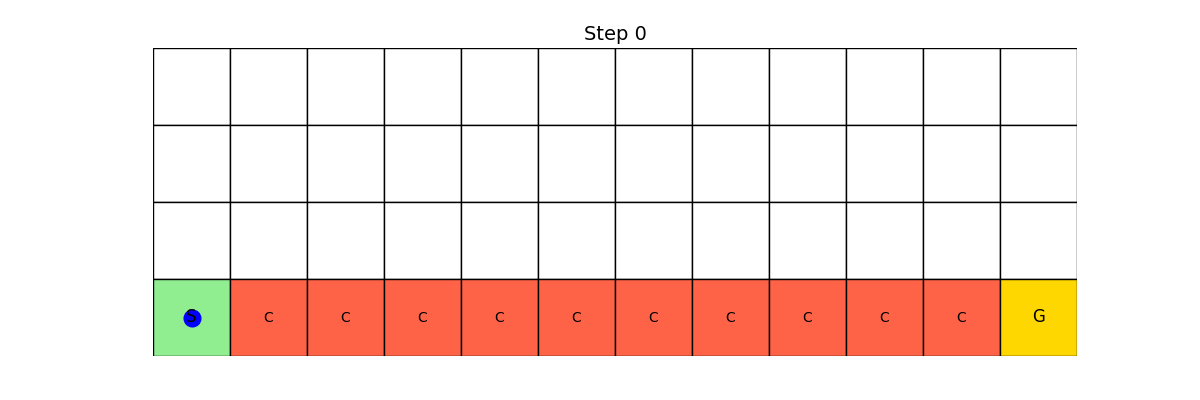

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import Image, display, Markdown
from google.colab import files
import zipfile

# Cliff fall example
display(Markdown("### Cliff Fall Example"))
save_episode_gif([0, 3, 3, 3, 1], filename="cliff_fall.gif", interval=500)
display(Image(filename="cliff_fall.gif", width=700))

# Goal path example
display(Markdown("### Goal Path Example"))
save_episode_gif([0] + [3] * 11 + [1], filename="goal_path.gif", interval=500)
display(Image(filename="goal_path.gif", width=700))

# Put both GIF files into one ZIP file and download it
with zipfile.ZipFile("cliff_walking_gifs.zip", "w") as zip_file:
    zip_file.write("cliff_fall.gif")
    zip_file.write("goal_path.gif")

files.download("cliff_walking_gifs.zip")



In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
from collections import deque
import matplotlib.pyplot as plt


In [ ]:
# Part 2: Deep Q-Network (DQN)
# This neural network maps a one-hot encoded state vector
# to Q-values for all possible actions.

class DQNetwork(nn.Module):
    def __init__(self, state_size, action_size):
        super(DQNetwork, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(state_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_size)
        )

    def forward(self, state):
        return self.network(state)


In [ ]:
# Test DQNetwork

env = CliffWalkingEnvironment()

state_size = env.grid_height * env.grid_width   # 4 * 12 = 48
action_size = 4                                 # up, down, left, right

q_network = DQNetwork(state_size, action_size)

state = env.reset()

state_index = env.get_state_representation()

state_vector = np.zeros(state_size)
state_vector[state_index] = 1

state_tensor = torch.FloatTensor(state_vector).unsqueeze(0)
q_values = q_network(state_tensor)

print("State size:", state_size)
print("Action size:", action_size)
print("State index:", state_index)
print("Input state tensor shape:", state_tensor.shape)
print("Output Q-values shape:", q_values.shape)
print("Q-values:", q_values.detach().numpy())


State size: 48
Action size: 4
State index: 36
Input state tensor shape: torch.Size([1, 48])
Output Q-values shape: torch.Size([1, 4])
Q-values: [[ 0.00293117 -0.06092944 -0.04549616 -0.06825683]]


In [ ]:
# Part 3: Replay Buffer
# This buffer stores past experiences and samples random mini-batches for DQN training.

from collections import deque
import random
import torch
import numpy as np

class ReplayBuffer:
    def __init__(self, capacity=10000):
        """
        Initialize replay buffer with fixed capacity.
        deque automatically removes old experiences when the buffer is full.
        """
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        """
        Store one experience tuple in the buffer.
        Each experience contains:
        (state, action, reward, next_state, done)
        """
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        """
        Randomly sample a batch of experiences and convert them to PyTorch tensors.
        """
        batch = random.sample(self.buffer, batch_size)

        states, actions, rewards, next_states, dones = zip(*batch)

        states = torch.FloatTensor(np.array(states))
        actions = torch.LongTensor(actions).unsqueeze(1)
        rewards = torch.FloatTensor(rewards).unsqueeze(1)
        next_states = torch.FloatTensor(np.array(next_states))
        dones = torch.FloatTensor(dones).unsqueeze(1)

        return states, actions, rewards, next_states, dones

    def __len__(self):
        """
        Return current number of stored experiences.
        """
        return len(self.buffer)


In [ ]:
# Test ReplayBuffer

buffer = ReplayBuffer(capacity=100)

state_size = 48
batch_size = 4

# Add sample experiences to the buffer
for i in range(10):
    state = np.zeros(state_size)
    next_state = np.zeros(state_size)

    state[i % state_size] = 1
    next_state[(i + 1) % state_size] = 1

    action = random.randint(0, 3)
    reward = -1
    done = False

    buffer.push(state, action, reward, next_state, done)

print("Current buffer size:", len(buffer))

states, actions, rewards, next_states, dones = buffer.sample(batch_size)

print("States shape:", states.shape)
print("Actions shape:", actions.shape)
print("Rewards shape:", rewards.shape)
print("Next states shape:", next_states.shape)
print("Dones shape:", dones.shape)


Current buffer size: 10
States shape: torch.Size([4, 48])
Actions shape: torch.Size([4, 1])
Rewards shape: torch.Size([4, 1])
Next states shape: torch.Size([4, 48])
Dones shape: torch.Size([4, 1])


In [ ]:
# Part 4: DQN Agent
# This agent uses two networks:
# - q_network: main network used for action selection and learning
# - target_network: stable target for computing DQN targets

class DQNAgent:
    def __init__(
        self,
        state_size,
        action_size,
        hidden_size=128,
        learning_rate=1e-3,
        gamma=0.99,
        epsilon=1.0,
        epsilon_min=0.05,
        epsilon_decay=0.995,
        buffer_capacity=10000,
        batch_size=64,
        target_update_frequency=10
    ):
        self.state_size = state_size
        self.action_size = action_size
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.batch_size = batch_size
        self.target_update_frequency = target_update_frequency
        self.step_count = 0

        self.q_network = DQNetwork(state_size, action_size)
        self.target_network = DQNetwork(state_size, action_size)
        self.update_target_network()

        self.optimizer = optim.Adam(self.q_network.parameters(), lr=learning_rate)
        self.criterion = nn.MSELoss()
        self.replay_buffer = ReplayBuffer(capacity=buffer_capacity)

    def select_action(self, state, training=True):
        if training and random.random() < self.epsilon:
            return random.randint(0, self.action_size - 1)

        state_tensor = torch.FloatTensor(state).unsqueeze(0)
        with torch.no_grad():
            q_values = self.q_network(state_tensor)
        return int(torch.argmax(q_values, dim=1).item())

    def store_transition(self, state, action, reward, next_state, done):
        self.replay_buffer.push(state, action, reward, next_state, done)

    def train_step(self):
        if len(self.replay_buffer) < self.batch_size:
            return None

        states, actions, rewards, next_states, dones = self.replay_buffer.sample(self.batch_size)

        current_q_values = self.q_network(states).gather(1, actions)

        with torch.no_grad():
            next_q_values = self.target_network(next_states).max(dim=1, keepdim=True)[0]
            target_q_values = rewards + self.gamma * next_q_values * (1 - dones)

        loss = self.criterion(current_q_values, target_q_values)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        self.step_count += 1
        if self.step_count % self.target_update_frequency == 0:
            self.update_target_network()

        return loss.item()

    def update_target_network(self):
        self.target_network.load_state_dict(self.q_network.state_dict())

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)


In [ ]:
# Helper function: one-hot encode state
def one_hot_state(state_index, state_size):
    state_vector = np.zeros(state_size, dtype=np.float32)
    state_vector[state_index] = 1.0
    return state_vector


In [ ]:
# Training loop
def train_dqn_agent(
    num_episodes=500,
    max_steps_per_episode=200,
    state_size=48,
    action_size=4,
    hidden_size=128
):
    env = CliffWalkingEnvironment()
    agent = DQNAgent(
        state_size=state_size,
        action_size=action_size,
        hidden_size=hidden_size
    )

    episode_rewards = []
    episode_losses = []
    epsilon_history = []

    for episode in range(num_episodes):
        state_index = env.reset()
        state = one_hot_state(state_index, state_size)

        total_reward = 0
        losses = []

        for step in range(max_steps_per_episode):
            action = agent.select_action(state, training=True)

            next_state_index, reward, done, _ = env.step(action)
            next_state = one_hot_state(next_state_index, state_size)

            agent.store_transition(state, action, reward, next_state, float(done))

            loss = agent.train_step()
            if loss is not None:
                losses.append(loss)

            state = next_state
            total_reward += reward

            if done:
                break

        agent.decay_epsilon()

        episode_rewards.append(total_reward)
        episode_losses.append(np.mean(losses) if len(losses) > 0 else np.nan)
        epsilon_history.append(agent.epsilon)

        if (episode + 1) % 10 == 0:
            print(
                f"Episode {episode + 1}/{num_episodes} | "
                f"Reward: {total_reward:.1f} | "
                f"Epsilon: {agent.epsilon:.4f} | "
                f"Avg Loss: {episode_losses[-1]}"
            )

    return agent, episode_rewards, episode_losses, epsilon_history


In [ ]:
# Run training
agent, episode_rewards, episode_losses, epsilon_history = train_dqn_agent(
    num_episodes=500,
    max_steps_per_episode=200,
    state_size=48,
    action_size=4,
    hidden_size=128
)


Episode 10/500 | Reward: -101.0 | Epsilon: 0.9511 | Avg Loss: 1148.7056274414062
Episode 20/500 | Reward: -103.0 | Epsilon: 0.9046 | Avg Loss: 871.8281860351562
Episode 30/500 | Reward: -106.0 | Epsilon: 0.8604 | Avg Loss: 272.97838701520647
Episode 40/500 | Reward: -107.0 | Epsilon: 0.8183 | Avg Loss: 16.574477434158325
Episode 50/500 | Reward: -110.0 | Epsilon: 0.7783 | Avg Loss: 0.8747435537251559
Episode 60/500 | Reward: -129.0 | Epsilon: 0.7403 | Avg Loss: 0.4456258291999499
Episode 70/500 | Reward: -108.0 | Epsilon: 0.7041 | Avg Loss: 0.42605431212319267
Episode 80/500 | Reward: -112.0 | Epsilon: 0.6696 | Avg Loss: 0.12834608382903612
Episode 90/500 | Reward: -100.0 | Epsilon: 0.6369 | Avg Loss: 22.15972900390625
Episode 100/500 | Reward: -48.0 | Epsilon: 0.6058 | Avg Loss: 1.4414001618112837
Episode 110/500 | Reward: -110.0 | Epsilon: 0.5762 | Avg Loss: 0.9660887718200684
Episode 120/500 | Reward: -103.0 | Epsilon: 0.5480 | Avg Loss: 0.48584262281656265
Episode 130/500 | Reward:

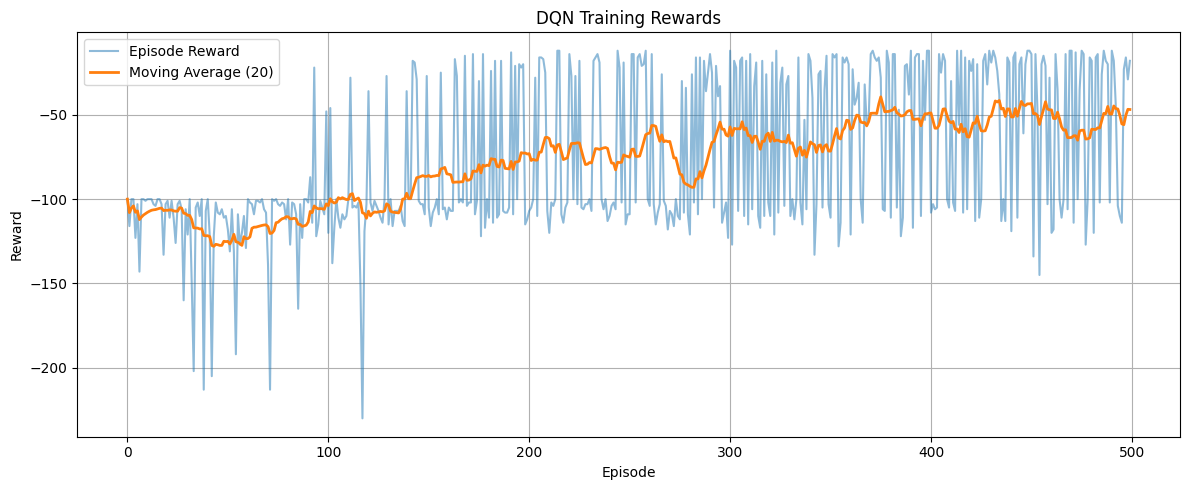

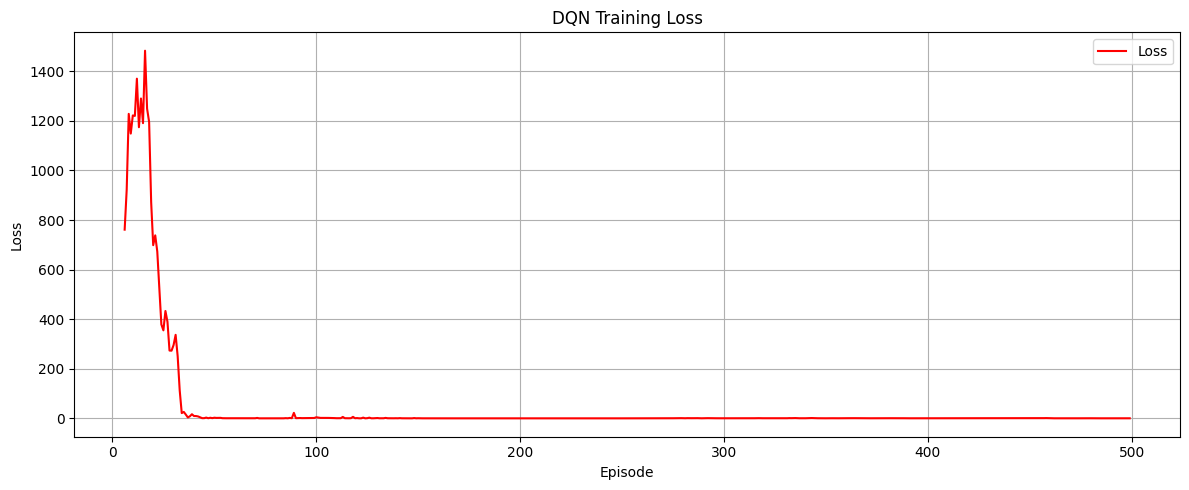

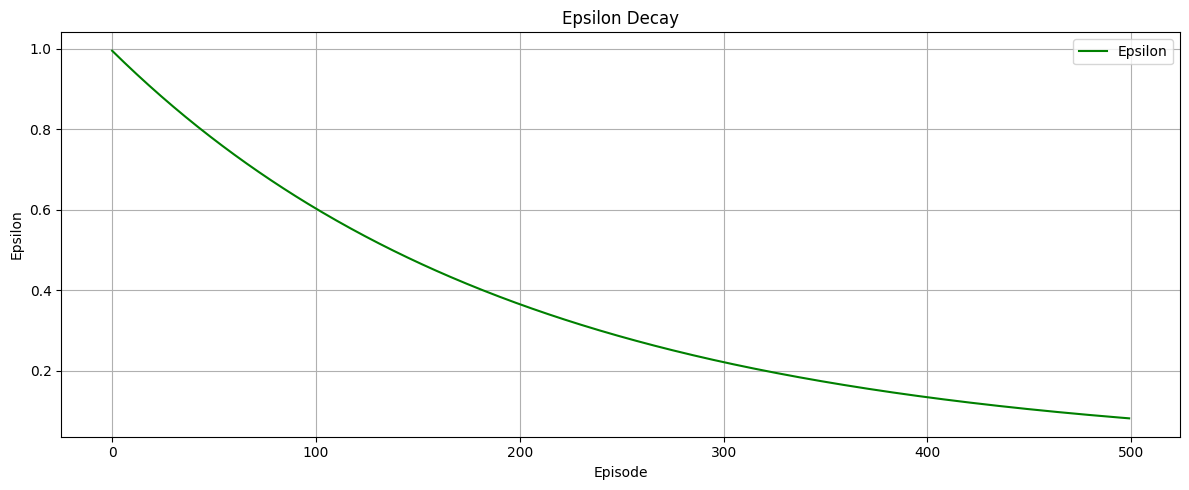

In [ ]:
# Plot and save training curves
import os

def moving_average(values, window=20):
    values = np.array(values, dtype=np.float32)
    result = []
    for i in range(len(values)):
        start = max(0, i - window + 1)
        result.append(np.mean(values[start:i+1]))
    return np.array(result)

reward_ma = moving_average(episode_rewards, window=20)

plt.figure(figsize=(12, 5))
plt.plot(episode_rewards, label="Episode Reward", alpha=0.5)
plt.plot(reward_ma, label="Moving Average (20)", linewidth=2)
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("DQN Training Rewards")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("dqn_rewards.png", dpi=200)
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(episode_losses, color="red", label="Loss")
plt.xlabel("Episode")
plt.ylabel("Loss")
plt.title("DQN Training Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("dqn_loss.png", dpi=200)
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(epsilon_history, color="green", label="Epsilon")
plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.title("Epsilon Decay")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("dqn_epsilon.png", dpi=200)
plt.show()


In [ ]:
# Evaluation episode without exploration
def evaluate_agent(agent, max_steps=100):
    env = CliffWalkingEnvironment()
    state_index = env.reset()
    state = one_hot_state(state_index, agent.state_size)

    frames = [env.agent_position]
    total_reward = 0
    done = False

    for _ in range(max_steps):
        action = agent.select_action(state, training=False)
        next_state_index, reward, done, _ = env.step(action)
        state = one_hot_state(next_state_index, agent.state_size)

        frames.append(env.agent_position)
        total_reward += reward

        if done:
            break

    return env, frames, total_reward, done


In [ ]:
# Save evaluation GIF
def save_agent_episode_gif(agent, filename="dqn_agent_episode.gif", interval=500, max_steps=100):
    env = CliffWalkingEnvironment()
    state_index = env.reset()
    state = one_hot_state(state_index, agent.state_size)

    positions = [env.agent_position]
    rewards = [None]
    dones = [False]

    for _ in range(max_steps):
        action = agent.select_action(state, training=False)
        next_state_index, reward, done, _ = env.step(action)
        state = one_hot_state(next_state_index, agent.state_size)

        positions.append(env.agent_position)
        rewards.append(reward)
        dones.append(done)

        if done:
            break

    fig, ax = plt.subplots(figsize=(12, 4))

    def update(frame):
        env.agent_position = positions[frame]
        draw_env(ax, env)
        title = f"Step {frame}"
        if frame > 0:
            title += f" | Reward: {rewards[frame]} | Done: {dones[frame]}"
        ax.set_title(title, fontsize=14)

    anim = FuncAnimation(fig, update, frames=len(positions), interval=interval, repeat=False)
    anim.save(filename, writer=PillowWriter(fps=max(1, 1000 // interval)))
    plt.close(fig)
    print(f"Saved GIF as: {filename}")
    return FileLink(filename)


In [ ]:
# Create final animation
save_agent_episode_gif(agent, filename="dqn_final_policy.gif", interval=500, max_steps=100)


Saved GIF as: dqn_final_policy.gif


/content/dqn_final_policy.gif

Saved GIF as: dqn_final_policy.gif


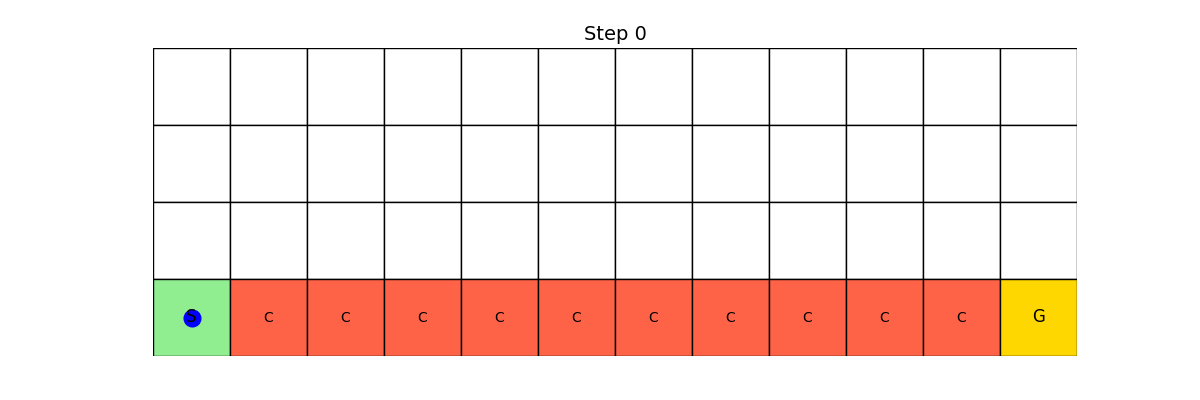

Added: dqn_rewards.png
Added: dqn_loss.png
Added: dqn_epsilon.png
Added: dqn_final_policy.gif

Created ZIP file: dqn_part4_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import Image, display, FileLink
from google.colab import files
import zipfile
import os

# Make sure final policy GIF is created
gif_filename = "dqn_final_policy.gif"
save_agent_episode_gif(agent, filename=gif_filename, interval=500, max_steps=100)

# Display GIF inside Colab output
display(Image(filename=gif_filename, width=700))

# Files that should be included in ZIP
output_files = [
    "dqn_rewards.png",
    "dqn_loss.png",
    "dqn_epsilon.png",
    "dqn_final_policy.gif"
]

# Create ZIP file
zip_filename = "dqn_part4_outputs.zip"

with zipfile.ZipFile(zip_filename, "w") as zip_file:
    for file_name in output_files:
        if os.path.exists(file_name):
            zip_file.write(file_name)
            print(f"Added: {file_name}")
        else:
            print(f"Warning: {file_name} not found")

print(f"\nCreated ZIP file: {zip_filename}")

# Download ZIP file
files.download(zip_filename)


In [ ]:
def safe_env_step(env, action):
    result = env.step(action)
    if len(result) == 4:
        next_state, reward, done, _ = result
    else:
        next_state, reward, done = result
    return next_state, reward, done


def make_dqn_state(state_index, state_size):
    return one_hot_state(state_index, state_size)


class DoubleDQNAgent(DQNAgent):
    def train_step(self):
        if len(self.replay_buffer) < self.batch_size:
            return None

        states, actions, rewards, next_states, dones = self.replay_buffer.sample(self.batch_size)

        states = torch.FloatTensor(states).view(self.batch_size, -1)
        next_states = torch.FloatTensor(next_states).view(self.batch_size, -1)

        actions = torch.LongTensor(actions).view(-1, 1)
        rewards = torch.FloatTensor(rewards).view(-1)
        dones = torch.FloatTensor(dones).view(-1)

        current_q_values = self.q_network(states).gather(1, actions).squeeze(1)

        with torch.no_grad():
            next_actions = self.q_network(next_states).argmax(dim=1, keepdim=True)
            next_q_values = self.target_network(next_states).gather(1, next_actions).squeeze(1)
            target_q_values = rewards + self.gamma * next_q_values * (1 - dones)

        if hasattr(self, "loss_fn"):
            loss = self.loss_fn(current_q_values, target_q_values)
        else:
            loss = self.criterion(current_q_values, target_q_values)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.item()


In [ ]:
double_env = CliffWalkingEnvironment()

double_agent = DoubleDQNAgent(
    state_size=48,
    action_size=4,
    hidden_size=128,
    learning_rate=0.001,
    gamma=0.99,
    epsilon=1.0,
    epsilon_decay=0.995,
    epsilon_min=0.05,
    buffer_capacity=10000,
    batch_size=64
)

double_dqn_rewards = []
double_dqn_losses = []
double_dqn_epsilons = []

num_episodes = 500
max_steps = 200
target_update_frequency = 10

for episode in range(num_episodes):
    state_index = double_env.reset()
    state = make_dqn_state(state_index, double_agent.state_size)

    total_reward = 0
    episode_losses = []

    for step in range(max_steps):
        action = double_agent.select_action(state)

        next_state_index, reward, done = safe_env_step(double_env, action)
        next_state = make_dqn_state(next_state_index, double_agent.state_size)

        double_agent.store_transition(state, action, reward, next_state, done)
        loss = double_agent.train_step()

        if loss is not None:
            episode_losses.append(loss)

        state = next_state
        total_reward += reward

        if done:
            break

    if episode % target_update_frequency == 0:
        double_agent.update_target_network()

    double_agent.epsilon = max(
        double_agent.epsilon_min,
        double_agent.epsilon * double_agent.epsilon_decay
    )

    double_dqn_rewards.append(total_reward)
    double_dqn_losses.append(np.mean(episode_losses) if episode_losses else 0)
    double_dqn_epsilons.append(double_agent.epsilon)

    if (episode + 1) % 50 == 0:
        avg_reward = np.mean(double_dqn_rewards[-50:])
        print(
            f"Double DQN Episode {episode + 1}/{num_episodes}, "
            f"Avg Reward: {avg_reward:.2f}, "
            f"Epsilon: {double_agent.epsilon:.3f}"
        )


Double DQN Episode 50/500, Avg Reward: -113.40, Epsilon: 0.778
Double DQN Episode 100/500, Avg Reward: -125.32, Epsilon: 0.606
Double DQN Episode 150/500, Avg Reward: -112.08, Epsilon: 0.471
Double DQN Episode 200/500, Avg Reward: -84.96, Epsilon: 0.367
Double DQN Episode 250/500, Avg Reward: -65.60, Epsilon: 0.286
Double DQN Episode 300/500, Avg Reward: -59.38, Epsilon: 0.222
Double DQN Episode 350/500, Avg Reward: -36.98, Epsilon: 0.173
Double DQN Episode 400/500, Avg Reward: -27.42, Epsilon: 0.135
Double DQN Episode 450/500, Avg Reward: -38.10, Epsilon: 0.105
Double DQN Episode 500/500, Avg Reward: -26.52, Epsilon: 0.082


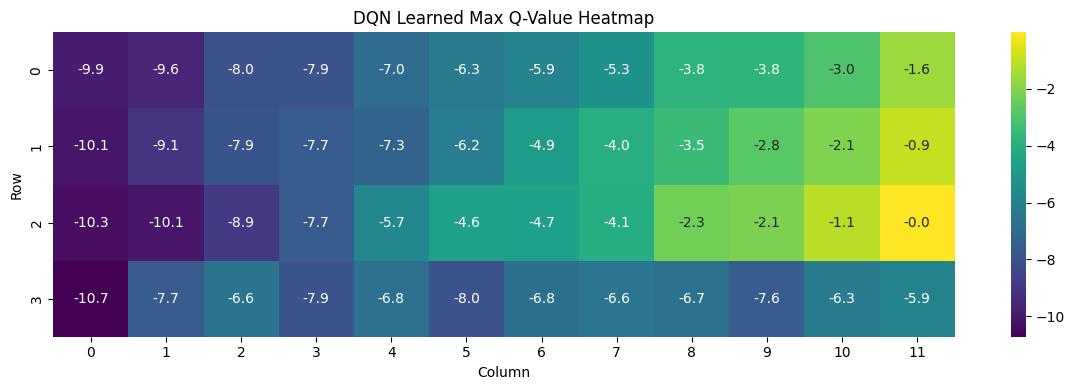

In [ ]:
import seaborn as sns

def plot_q_value_heatmap(agent, save_path="dqn_qvalue_heatmap.png"):
    rows, cols = 4, 12
    q_max_grid = np.zeros((rows, cols))

    for state_index in range(rows * cols):
        state = make_dqn_state(state_index, agent.state_size)
        state_tensor = torch.FloatTensor(state)

        if state_tensor.dim() == 1:
            state_tensor = state_tensor.unsqueeze(0)

        with torch.no_grad():
            q_values = agent.q_network(state_tensor).cpu().numpy()[0]

        row, col = divmod(state_index, cols)
        q_max_grid[row, col] = np.max(q_values)

    plt.figure(figsize=(12, 4))
    sns.heatmap(q_max_grid, annot=True, fmt=".1f", cmap="viridis")
    plt.title("DQN Learned Max Q-Value Heatmap")
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

plot_q_value_heatmap(agent)


In [ ]:
class QLearningAgent:
    def __init__(
        self,
        state_size,
        action_size,
        learning_rate=0.1,
        gamma=0.99,
        epsilon=1.0,
        epsilon_decay=0.995,
        epsilon_min=0.05
    ):
        self.state_size = state_size
        self.action_size = action_size
        self.learning_rate = learning_rate
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min
        self.q_table = np.zeros((state_size, action_size))

    def select_action(self, state, training=True):
        if training and np.random.random() < self.epsilon:
            return np.random.randint(self.action_size)
        return np.argmax(self.q_table[state])

    def update(self, state, action, reward, next_state, done):
        best_next_action = np.argmax(self.q_table[next_state])

        td_target = reward
        if not done:
            td_target += self.gamma * self.q_table[next_state, best_next_action]

        td_error = td_target - self.q_table[state, action]
        self.q_table[state, action] += self.learning_rate * td_error

    def decay_epsilon(self):
        self.epsilon = max(
            self.epsilon_min,
            self.epsilon * self.epsilon_decay
        )


In [ ]:
q_env = CliffWalkingEnvironment()

q_agent = QLearningAgent(
    state_size=48,
    action_size=4,
    learning_rate=0.1,
    gamma=0.99,
    epsilon=1.0,
    epsilon_decay=0.995,
    epsilon_min=0.05
)

q_learning_rewards = []
q_learning_epsilons = []

num_episodes = 500
max_steps = 200

for episode in range(num_episodes):
    state = q_env.reset()
    total_reward = 0

    for step in range(max_steps):
        action = q_agent.select_action(state, training=True)

        next_state, reward, done = safe_env_step(q_env, action)

        q_agent.update(state, action, reward, next_state, done)

        state = next_state
        total_reward += reward

        if done:
            break

    q_agent.decay_epsilon()

    q_learning_rewards.append(total_reward)
    q_learning_epsilons.append(q_agent.epsilon)

    if (episode + 1) % 50 == 0:
        avg_reward = np.mean(q_learning_rewards[-50:])
        print(
            f"Q-learning Episode {episode + 1}/{num_episodes}, "
            f"Avg Reward: {avg_reward:.2f}, "
            f"Epsilon: {q_agent.epsilon:.3f}"
        )


Q-learning Episode 50/500, Avg Reward: -114.56, Epsilon: 0.778
Q-learning Episode 100/500, Avg Reward: -118.98, Epsilon: 0.606
Q-learning Episode 150/500, Avg Reward: -117.94, Epsilon: 0.471
Q-learning Episode 200/500, Avg Reward: -107.36, Epsilon: 0.367
Q-learning Episode 250/500, Avg Reward: -97.66, Epsilon: 0.286
Q-learning Episode 300/500, Avg Reward: -74.98, Epsilon: 0.222
Q-learning Episode 350/500, Avg Reward: -68.00, Epsilon: 0.173
Q-learning Episode 400/500, Avg Reward: -56.78, Epsilon: 0.135
Q-learning Episode 450/500, Avg Reward: -35.52, Epsilon: 0.105
Q-learning Episode 500/500, Avg Reward: -38.98, Epsilon: 0.082


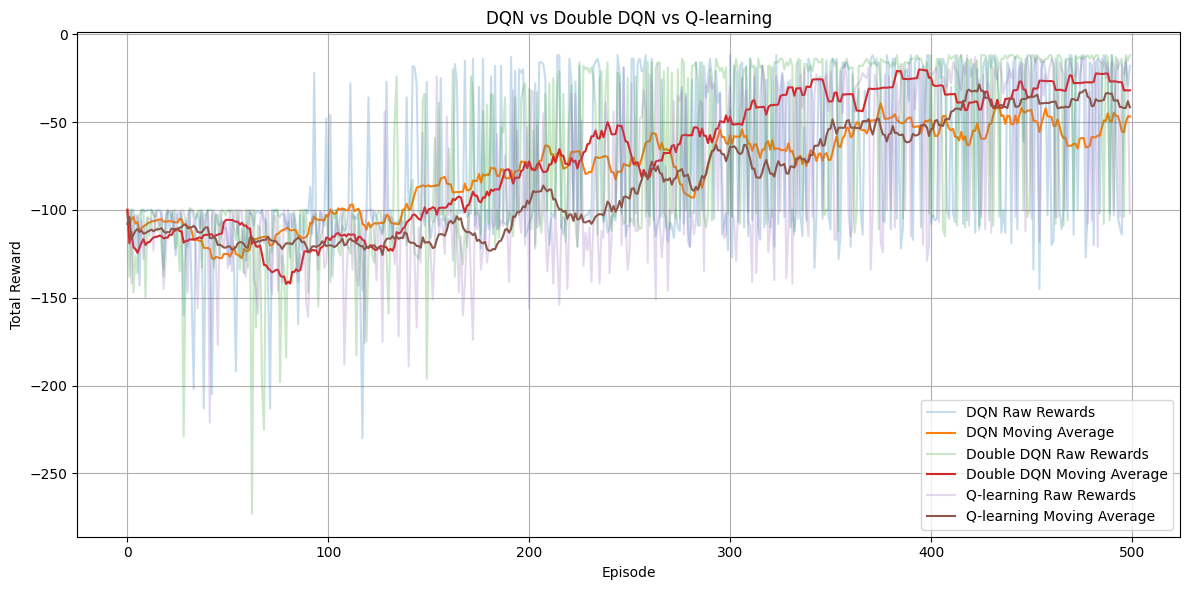

In [51]:
plt.figure(figsize=(12, 6))

plt.plot(episode_rewards, alpha=0.25, label="DQN Raw Rewards")
plt.plot(
    range(len(moving_average(episode_rewards))),
    moving_average(episode_rewards),
    label="DQN Moving Average"
)

plt.plot(double_dqn_rewards, alpha=0.25, label="Double DQN Raw Rewards")
plt.plot(
    range(len(moving_average(double_dqn_rewards))),
    moving_average(double_dqn_rewards),
    label="Double DQN Moving Average"
)

plt.plot(q_learning_rewards, alpha=0.25, label="Q-learning Raw Rewards")
plt.plot(
    range(len(moving_average(q_learning_rewards))),
    moving_average(q_learning_rewards),
    label="Q-learning Moving Average"
)

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("DQN vs Double DQN vs Q-learning")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("dqn_double_dqn_qlearning_comparison.png", dpi=150)
plt.show()
